# 11 Von der Anomalie zur Handlungsempfehlung

- Ausgangspunkt Notebook 10: netzweites und stationseigenes Erwartungswertmodell bestehen die Begehungsvalidierung und messen Verschiedenes (Spearman 0,14).
- Problem: 55 von 100 Stationen ohne eindeutiges Muster, ohne Muster keine Empfehlung.
- Ziel: je auffälliger Station Muster, Maßnahme, nachvollziehbarer Schweregrad und eine priorisierte Liste ohne Adressen.
- Logik in `src/empfehlung.py` und `src/freitext.py`, Tests in `tests/test_empfehlung.py` und `tests/test_freitext.py`.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import anomalie as an
from src import clustervalidierung as cvl
from src import empfehlung as em
from src import freitext as ft
from src import load_begehungen as lb
from src import nb00_daten as nb00
from src import priority as pr
from src import tagespanel as tp
from src import weather

from sklearn.preprocessing import StandardScaler

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)

METER_DIR = ROOT / "data" / "processed" / "real_meters"
SPALTEN = {
    "Energy (kWh)": "energy", "Volume flow (l/h)": "flow",
    "Power (kW)": "power", "Temperature difference (°C)": "dt",
    "Flow temperature (°C)": "vl", "Return temperature (°C)": "rt",
    "Volume (m³)": "volume",
}
t0 = time.time()


def tick(txt):
    print(f"[{time.time() - t0:6.0f}s] {txt}")

## 1 Rechenbasis

- Stundenreihen aus Notebook 00 über `nb00.lade_serien(METER_DIR, leere_stunden_entfernen=False)`, 100 Zähler bis 11.07.2025, fünf davon mit Nachlieferung bis 20.07.2026.
- Tagespanel mit denselben Aufrufen wie in Notebook 10 neu gerechnet (Seed 42).

In [2]:
#PANELBAU
#Raster aus NB 00 unveraendert, nur leere Zaehlerstaende ergaenzt
serien = nb00.lade_serien(METER_DIR, leere_stunden_entfernen=False)
von = min(d.index[0] for d in serien.values() if len(d))
bis = max(d.index[-1] for d in serien.values() if len(d))
t_out = weather.load_outdoor_temperature(von, bis, allow_download=False)
tick(f"{len(serien)} Zaehlerreihen, {von:%Y-%m-%d} bis {bis:%Y-%m-%d}")

panel_h, ausschluss = cvl.lade_stundenpanel(METER_DIR)
panel_h = cvl.mit_kontext(panel_h, t_out)
X = StandardScaler().fit_transform(panel_h[cvl.BETRIEBS_FEATURES])
panel_h["cluster"] = cvl.fit_minibatch_kmeans(X, 5, n_init=10)
profil_h = cvl.zentroid_profil(panel_h[cvl.BETRIEBS_FEATURES].to_numpy(),
                               panel_h["cluster"].to_numpy(),
                               cvl.BETRIEBS_FEATURES)
kandidat = profil_h[profil_h["flow_norm"] > 0.3]
KURZ = int(kandidat["dt"].idxmin())
ANTEIL = f"anteil_c{KURZ}"
tick(f"Stundencluster, Kurzschlussverdacht ist Cluster {KURZ}")

panel = tp.baue_tagespanel(serien, stundencluster=panel_h, t_out=t_out)
panel, info_netz = an.erwartungsmodell_netz(panel)
panel, bilanz_station = an.erwartungsmodell_station(panel)
DETEKTOREN = [f"score_{an.D_RESID_NETZ}", f"score_{an.D_RESID_STATION}"]
schwellen = {}
for d in DETEKTOREN:
    panel, s = an.persistente_tage(panel, d)
    schwellen[d] = s
panel.attrs["kurzschlusscluster"] = KURZ
tick(f"Tagespanel {panel.shape}, {panel['meter'].nunique()} Zaehler, "
     f"r2 netzweit {info_netz['r2']:.3f}")
print("Tagesschwellen:", {k.replace('score_', ''): round(v, 2)
                          for k, v in schwellen.items()})

[    28s] 100 Zaehlerreihen, 2021-05-31 bis 2026-07-20
[    95s] Stundencluster, Kurzschlussverdacht ist Cluster 4
[   760s] Tagespanel (105513, 51), 100 Zaehler, r2 netzweit 0.046
Tagesschwellen: {'residuum_netz': 22.72, 'residuum_station': 8.21}


## 2 Warum so viele Stationen ohne Muster blieben

- Alte Zuordnung: Quantilsregeln über alle Stationen, ein Muster greift nur, wenn alle Bedingungen zugleich erfüllt sind. Unten gegen die persistente Auffälligkeit gekreuzt.

In [3]:
MUSTERSPALTEN = ["rt_vl_kopplung", "dt_mean_loaded", "rt_traege_anteil",
                 "rt_d1_abs_mean", "rt_d2_abs_mean", "flow_median",
                 "last_anteil", "score_residuum_netz"]
profil_alt = an.stationsprofil(panel, MUSTERSPALTEN)
muster_alt = an.muster_je_station(profil_alt)
print("Alte Musterzuordnung ueber alle Stationen")
print(muster_alt["muster"].value_counts().to_string())

kenn_roh = em.kennzahlen(panel, ANTEIL)
auff_tab = pd.DataFrame({
    "meter": kenn_roh["meter"].astype(int),
    "auffaellig": em.auffaellige_stationen(kenn_roh).to_numpy()})
kreuz = muster_alt.merge(auff_tab, on="meter", how="left")
print()
print("Muster gegen persistente Auffaelligkeit")
print(pd.crosstab(kreuz["muster"], kreuz["auffaellig"]).to_string())

Alte Musterzuordnung ueber alle Stationen
muster
kein eindeutiges Muster                                                55
unruhige Regelung                                                      18
Ruecklauf ueber Erwartung ohne weiteres Merkmal                        15
Ruecklauf reagiert kaum, Verdacht festsitzendes oder offenes Ventil     7
Ruecklauf folgt dem Vorlauf, Verdacht hydraulischer Kurzschluss         4
Durchfluss ohne nennenswerte Abnahme                                    1

Muster gegen persistente Auffaelligkeit
auffaellig                                                           False  True 
muster                                                                           
Durchfluss ohne nennenswerte Abnahme                                     1      0
Ruecklauf folgt dem Vorlauf, Verdacht hydraulischer Kurzschluss          2      2
Ruecklauf reagiert kaum, Verdacht festsitzendes oder offenes Ventil      6      1
Ruecklauf ueber Erwartung ohne weiteres Merkmal         

- 46 der 55 Stationen ohne Muster sind nicht persistent auffällig, dort ist „kein Muster“ richtig.
- Von 26 persistent auffälligen Stationen bleiben 21 ohne verwertbare Diagnose (9 ohne Muster, 12 mit Auffangmuster).
- Zweite Ursache: ein oberes Quintil trifft 20 von 100 Stationen, zwei unabhängige Bedingungen zusammen im Mittel nur 4.
- Folgerung: Zuordnung nur auf auffälligen Stationen, gewichtete Evidenz statt harter Konjunktion.

## 3 Neuer Musterkatalog

- Auffällig: nach einem der beiden Detektoren mehr als 10 % der Tage persistent auffällig.
- Evidenz eines Musters = gewichtetes Mittel der rangbasierten z-Werte seiner Indikatoren. Es gewinnt das Muster mit der höchsten Evidenz ab 0,6.
- Rang statt Median und MAD, weil z. B. der Volumenstrom (Median 38 l/h, Maximum rund 14.500 l/h) sonst extreme z-Werte liefert.
- Sieben Muster, die zwei generischen greifen nur, wenn kein spezifisches reicht.

In [4]:
kenn = em.kennzahlen(panel, ANTEIL)
eff = em.effizienz(panel, kenn)
print(f"Kennzahlenprofil {kenn.shape}")
print(kenn.describe().round(2).to_string())

Kennzahlenprofil (100, 24)
             meter      rt     dt    last      flow    kopp      d1      d2  traege   reak   perf  spanne   power   n_tage  score_netz  pers_netz  score_station  pers_station  rt_winter  dt_winter  rt_sommer  last_sommer  rt_delta_saison  anteil_kurzschluss
count       100.00  100.00  94.00  100.00    100.00  100.00  100.00  100.00   98.00  98.00  98.00  100.00  100.00   100.00      100.00     100.00           98.0        100.00     100.00      94.00     100.00       100.00           100.00               93.00
mean   72208143.68   46.32  23.52    0.25    436.74    0.59    4.61    7.53    0.01   0.68  24.60   22.75    7.75  1053.13       -0.63       0.08            0.0          0.06      46.37      25.58      46.82         0.12             0.46                0.11
std    10497807.45   12.41   7.65    0.25   1891.75    0.23    2.81    4.88    0.03   0.60   9.92    9.64   36.57   337.93       10.65       0.18            0.0          0.09      11.55       8.15   

In [5]:
bilanz = em.musterbilanz(kenn)
print("Musterzuordnung, neu")
print(bilanz.to_string(index=False))

n_auff = int(bilanz.loc[bilanz["auffaellig"], "n_stationen"].sum())
ohne = int(bilanz.loc[bilanz["muster"] == em.OHNE_MUSTER,
                      "n_stationen"].sum())
print(f"\nauffaellige Stationen: {n_auff}")
print(f"davon ohne klares Muster: {ohne} "
      f"({100 * ohne / n_auff:.0f} Prozent)")

Musterzuordnung, neu
                                                                muster  auffaellig  n_stationen
       Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss        True            9
Hoher Ruecklauf im Sommer, Verdacht Zirkulations- oder Speicherverlust        True            6
                                                     Unruhige Regelung        True            4
                 Verschlechterung gegenueber dem eigenen Normalbetrieb        True            3
                       Keine nennenswerte Abnahme bei warmem Ruecklauf        True            2
   Ruecklauf reagiert kaum, Verdacht festsitzendes oder offenes Ventil        True            1
                                         auffaellig ohne klares Muster        True            1
                                                          unauffaellig       False           74

auffaellige Stationen: 26
davon ohne klares Muster: 1 (4 Prozent)


In [6]:
treffer = em.trefferliste(kenn, eff)
spalten = ["meter", "muster", "stufe", "punkte", "evidenz", "abstand",
           "persistenz", "abweichung_k", "mehrdurchfluss"]
print(treffer[spalten].round(2).to_string(index=False))

   meter                                                                 muster   stufe  punkte  evidenz  abstand  persistenz  abweichung_k  mehrdurchfluss
68956351        Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss    hoch   100.0     1.82     0.66        0.77         21.07            3.98
72135480        Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss    hoch   100.0     1.72     0.78        0.52         22.60            3.47
72167793        Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss    hoch   100.0     1.54     0.78        0.62         23.95            2.96
80912182        Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss    hoch   100.0     1.79     0.79        0.83         27.33            3.59
72167782        Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss    hoch   100.0     1.57     0.34        0.77         26.40            2.99
48090145 Hoher Ruecklauf im Sommer, Verdacht Zirkulations- oder 

- 26 auffällige Stationen, nur 68956373 ohne Muster.
- Häufigstes Muster: Kurzschlussverdacht (9 Stationen), darunter alle fünf mit 100 Punkten.
- An der Spitze 68956351 mit dem drei Jahre offenen Ventil, hier als Kurzschluss eingeordnet. Beides sieht im Messbild ähnlich aus (viel Durchfluss, kaum Auskühlung).
- Unsicherheit = Abstand zwischen bestem und zweitbestem Muster. Nahe null heißt: zweites Muster bei der Begehung mitprüfen.

In [7]:
knapp = treffer[treffer["abstand"] < 0.3]
print(f"Zuordnungen mit Abstand unter 0,3: {len(knapp)} von {len(treffer)}")
print(treffer["abstand"].describe().round(2).to_string())
print()
print(knapp[["meter", "muster", "zweitmuster", "abstand"]].round(2)
      .to_string(index=False))

Zuordnungen mit Abstand unter 0,3: 5 von 26
count    25.00
mean      0.70
std       0.48
min       0.02
25%       0.35
50%       0.66
75%       0.97
max       2.02

   meter                                                                 muster                                                            zweitmuster  abstand
68956360        Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss Hoher Ruecklauf im Sommer, Verdacht Zirkulations- oder Speicherverlust     0.02
41566331 Hoher Ruecklauf im Sommer, Verdacht Zirkulations- oder Speicherverlust                        Keine nennenswerte Abnahme bei warmem Ruecklauf     0.07
68956372 Hoher Ruecklauf im Sommer, Verdacht Zirkulations- oder Speicherverlust        Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss     0.17
69513891 Hoher Ruecklauf im Sommer, Verdacht Zirkulations- oder Speicherverlust                                                      Unruhige Regelung     0.18
72167783                        Kei

## 4 Freitexte der Begehungen kodieren

- 66 Begehungszeilen, 57 mit Freitext.
- Regelbasiert über Schlüsselwortlisten in `src/freitext.py`, jede Zuordnung auf das auslösende Wort rückführbar, Verneinungen werden berücksichtigt.
- Das Prüfblatt zeigt nur Kategorien und Trefferwörter, nicht den Rohtext.

In [8]:
begehungen = lb.load_begehungen()
kodiert = ft.kodiere_tabelle(begehungen)
print(f"{len(begehungen)} Begehungszeilen")
print(ft.kodierbilanz(kodiert).to_string(index=False))

66 Begehungszeilen
      stufe  n_texte   anteil
  eindeutig       24 0.363636
ohne Befund       20 0.303030
 mehrdeutig       13 0.196970
       leer        9 0.136364


In [9]:
rang_text = ft.rangliste_begehungen(kodiert)
print("Rangliste aus den Begehungstexten")
print(rang_text.to_string(index=False))

Rangliste aus den Begehungstexten
                                     kategorie  n_texte  anteil_texte
                    kein Fehlerhinweis im Text       29      0.439394
       Regelung defekt oder falsch eingestellt       17      0.257576
             Pumpe oder Zirkulation fehlerhaft       10      0.151515
Hydraulik oder Volumenstrom falsch eingeregelt        8      0.121212
                      Messtechnik oder Zaehler        6      0.090909
        Schmutzfaenger oder Filter verschmutzt        6      0.090909
                           Daemmung mangelhaft        4      0.060606
         Sonstiger Defekt oder Reparaturbedarf        4      0.060606
      Vertragsleistung passt nicht zur Abnahme        2      0.030303


In [10]:
#Pruefblatt ohne den Rohtext: die Protokolle koennen Hinweise auf
#Gebaeude und Personen enthalten, die hier nichts zu suchen haben.
#Nachvollziehbar bleibt die Zuordnung ueber die ausloesenden Woerter.
blatt = ft.pruefblatt(kodiert).drop(columns=["text_kurz"])
print(blatt[blatt["stufe"] != "leer"].head(20).to_string(index=False))

 nr       stufe                                                                                                                 kategorien                                                                     treffer
  1  mehrdeutig                        Regelung defekt oder falsch eingestellt, Daemmung mangelhaft, Sonstiger Defekt oder Reparaturbedarf          anlagenkennziffer; daemmung fehlt; fahrweise; laeuft nicht; regler
  3  mehrdeutig                                          Regelung defekt oder falsch eingestellt, Vertragsleistung passt nicht zur Abnahme                       anlagenschema; leistung teilweise hoeher; vertraglich
  4  mehrdeutig                            Regelung defekt oder falsch eingestellt, Pumpe oder Zirkulation fehlerhaft, Daemmung mangelhaft                        daemmung fehlt; pumpe; zirkulationspumpe eingestellt
  5   eindeutig                                                                                      Sonstiger Defekt oder Reparaturbedarf  

- 5 von 26 Zuordnungen knapp (Abstand unter 0,3), meist mit dem Sommerrücklaufmuster.
- Freitexte: 24 eindeutig, 13 mehrdeutig, 20 ohne Fehlerhinweis, 9 leer. Häufigste Kategorien: Regelung (17), Pumpe oder Zirkulation (10), Hydraulik (8).

## 5 Zwei Ranglisten nebeneinander

- Eine Rangliste aus den Texten, eine aus den Messdaten. Nicht ineinander überführbar: die Begehungen betreffen andere Stationen, und Monteure sehen auch Dinge ohne Spur im Zähler.

In [11]:
rang_mess = em.rangliste_messdaten(treffer)
print("Rangliste aus den Messdaten")
print(rang_mess.round(3).to_string(index=False))

Rangliste aus den Messdaten
                                                                muster  n_stationen  n_hoch  n_mittel  n_niedrig  anteil
       Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss            9       8         1          0   0.346
Hoher Ruecklauf im Sommer, Verdacht Zirkulations- oder Speicherverlust            6       5         0          1   0.231
                                                     Unruhige Regelung            4       1         1          2   0.154
                 Verschlechterung gegenueber dem eigenen Normalbetrieb            3       0         1          2   0.115
                       Keine nennenswerte Abnahme bei warmem Ruecklauf            2       1         1          0   0.077
   Ruecklauf reagiert kaum, Verdacht festsitzendes oder offenes Ventil            1       1         0          0   0.038
                                         auffaellig ohne klares Muster            1       0         0          1   0.038


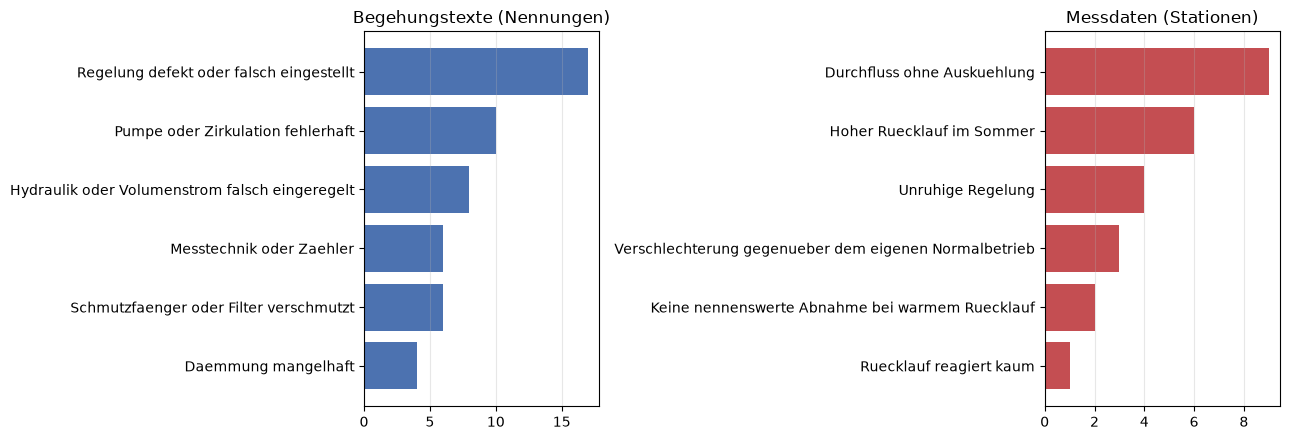

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
t = rang_text[rang_text["kategorie"] != ft.OHNE_BEFUND].head(6)
axes[0].barh(t["kategorie"][::-1], t["n_texte"][::-1], color="#4C72B0")
axes[0].set_title("Begehungstexte (Nennungen)")
m = rang_mess.head(6)
kurz = [s.split(",")[0] for s in m["muster"]]
axes[1].barh(kurz[::-1], m["n_stationen"][::-1], color="#C44E52")
axes[1].set_title("Messdaten (Stationen)")
for ax in axes:
    ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

- Messdaten: Kurzschlussverdacht 9 von 26, hoher Sommerrücklauf 6, unruhige Regelung 4. In den Texten steht dagegen die Regelung vorn.

## 6 Erklärbares Baummodell

- Zweck Erklärung, nicht Vorhersage. Zielgröße Rücklaufresiduum gegen die Netzerwartung, 52.572 Stationstage, Kreuzvalidierung hält ganze Stationen heraus.
- Spreizung ausgeschlossen, weil rechnerisch aus Vorlauf minus Rücklauf, zum Vergleich einmal mit.

In [13]:
X, y, gruppen = em.baumdaten(panel)
print(f"Merkmalsmatrix {X.shape}, Zielgroesse {y.name}")
baum = em.fitte_baum(X, y, tiefe=3)
print(em.baumtext(baum, X.columns))

Merkmalsmatrix (52572, 10), Zielgroesse score_residuum_netz
+-- flow_median <= 170.2
|   +-- power_mean <= 9.0
|   |   +-- flow_median <= 83.8
|   |   |   +-- Ruecklaufresiduum: [-5.5]
|   |   +-- flow_median >  83.8
|   |   |   +-- Ruecklaufresiduum: [-0.3]
|   +-- power_mean >  9.0
|   |   +-- power_mean <= 49.0
|   |   |   +-- Ruecklaufresiduum: [21.0]
|   |   +-- power_mean >  49.0
|   |   |   +-- Ruecklaufresiduum: [14.5]
+-- flow_median >  170.2
|   +-- power_mean <= 4.8
|   |   +-- last_anteil <= 0.5
|   |   |   +-- Ruecklaufresiduum: [27.8]
|   |   +-- last_anteil >  0.5
|   |   |   +-- Ruecklaufresiduum: [18.6]
|   +-- power_mean >  4.8
|   |   +-- power_mean <= 167.8
|   |   |   +-- Ruecklaufresiduum: [6.1]
|   |   +-- power_mean >  167.8
|   |   |   +-- Ruecklaufresiduum: [-5.0]



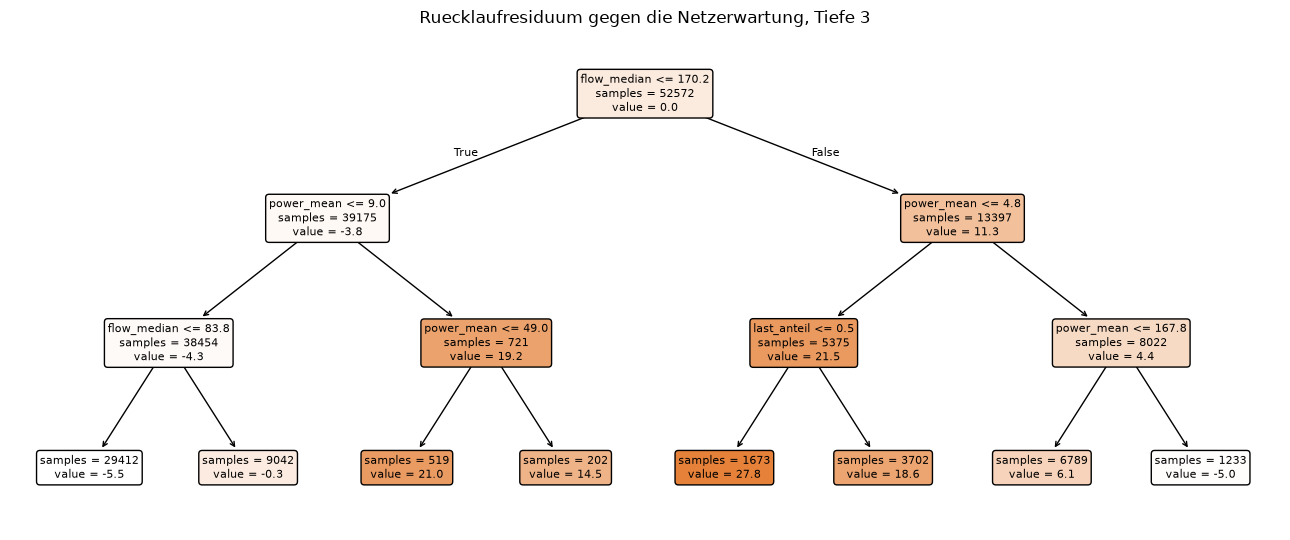

In [14]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(13, 5.5))
plot_tree(baum, feature_names=list(X.columns), filled=True, rounded=True,
          precision=1, fontsize=8, impurity=False, ax=ax)
ax.set_title("Ruecklaufresiduum gegen die Netzerwartung, Tiefe 3")
fig.tight_layout()
plt.show()

In [15]:
stab = em.baum_stabilitaet(X, y, gruppen, tiefe=3)
print("Kreuzvalidierung nach Stationen")
print(stab.round(3).to_string(index=False))
print(f"\nr2 ueber die Folds: {stab['r2_test'].mean():.3f} "
      f"plus minus {stab['r2_test'].std():.3f}")
print("Wurzelvariable je Fold:", ", ".join(sorted(set(stab["wurzel"]))))

Kreuzvalidierung nach Stationen
 fold  n_train  n_test  r2_test      wurzel  schwelle  wichtigste  anteil_wichtigste
    1    42060   10512    0.484 flow_median    170.25 flow_median              0.568
    2    42053   10519    0.399 flow_median    170.25 flow_median              0.636
    3    42045   10527    0.486 flow_median    170.25 flow_median              0.555
    4    42063   10509    0.324 flow_median    170.25 flow_median              0.596
    5    42067   10505    0.228 flow_median    202.25 flow_median              0.629

r2 ueber die Folds: 0.384 plus minus 0.110
Wurzelvariable je Fold: flow_median


In [16]:
Xs, ys, gs = em.baumdaten(panel, merkmale=em.BAUMMERKMALE_MIT_SPREIZUNG)
baum_s = em.fitte_baum(Xs, ys, tiefe=3)
stab_s = em.baum_stabilitaet(Xs, ys, gs, tiefe=3)
print("Vergleichsbaum mit Spreizung")
print(em.baumtext(baum_s, Xs.columns).split("\n")[0])
print(f"r2 ueber die Folds: {stab_s['r2_test'].mean():.3f}, "
      f"Wurzel: {', '.join(sorted(set(stab_s['wurzel'])))}")

Vergleichsbaum mit Spreizung
+-- dt_mean_loaded <= 21.9
r2 ueber die Folds: 0.562, Wurzel: dt_mean_loaded


- Wurzel in allen fünf Folds `flow_median` bei rund 170 l/h, r² auf herausgehaltenen Stationen 0,38 ± 0,11.
- Wärmster Ast: Durchfluss über 170 l/h bei Leistung bis 4,8 kW, Residuum +27,8 K. Passt zum Kurzschlussmuster.
- Mit Spreizung r² 0,56, der Gewinn ist überwiegend rechnerisch.

## 7 Schweregrad

- Drei offengelegte Komponenten: Abweichung in Kelvin (Gewicht 0,45), Persistenz (0,35), Mehrdurchfluss (0,20). Hoch ab 55 Punkten, mittel ab 30.
- Mehrdurchfluss = Rücklaufabweichung geteilt durch die Spreizung, anders als Verbrauch je Heizgradstunde unabhängig von der Hausgröße.

In [17]:
grad = em.schweregrad(kenn, eff)
spalten = ["meter", "abweichung_k", "komp_abweichung", "persistenz",
           "komp_persistenz", "mehrdurchfluss", "komp_effizienz",
           "punkte", "stufe"]
print(grad.sort_values("punkte", ascending=False)[spalten]
      .head(12).round(3).to_string(index=False))
print()
print(treffer["stufe"].value_counts().to_string())

   meter  abweichung_k  komp_abweichung  persistenz  komp_persistenz  mehrdurchfluss  komp_effizienz  punkte stufe
68956351        21.070            1.000       0.765            1.000           3.985           1.000   100.0  hoch
72167793        23.950            1.000       0.620            1.000           2.964           1.000   100.0  hoch
72167782        26.398            1.000       0.768            1.000           2.988           1.000   100.0  hoch
72135480        22.600            1.000       0.520            1.000           3.468           1.000   100.0  hoch
80912182        27.328            1.000       0.826            1.000           3.589           1.000   100.0  hoch
48090145        18.748            1.000       0.477            0.953             NaN             NaN    98.0  hoch
81062289        18.398            1.000       0.348            0.696           1.373           1.000    89.4  hoch
68956360        11.783            0.786       0.474            0.949           0

- 16 Stationen hoch, 4 mittel, 6 niedrig. Die fünf mit 100 Punkten sind gedeckelt und untereinander nicht sortiert.
- Ein Fehler ohne Spur im Rücklauf bekommt keine Punkte.

## 8 Trefferliste, Export und Priorisierung

- Export nur mit Zählernummern, `em.exportiere` verweigert Spalten mit Adress- oder Namensbezug.
- `src/priority.py` sagt, wo eine Begehung überfällig ist, die Trefferliste, wo der Betrieb heute auffällig ist. `pr.mit_empfehlung` stellt beides nebeneinander.

In [18]:
ziel = ROOT / "data" / "processed" / "empfehlungsliste.csv"
em.exportiere(treffer, str(ziel))
print(f"geschrieben: {ziel.relative_to(ROOT)}, {len(treffer)} Zeilen")
print("Spalten:", list(treffer.columns))

geschrieben: data\processed\empfehlungsliste.csv, 26 Zeilen
Spalten: ['meter', 'muster', 'stufe', 'punkte', 'massnahme', 'begruendung_kurz', 'evidenz', 'zweitmuster', 'abstand', 'persistenz', 'abweichung_k', 'mehrdurchfluss', 'verlust_kwh_je_kh', 'n_tage']


In [19]:
scores = pr.compute_scores()
kombiniert = pr.mit_empfehlung(scores, treffer)
vergleich = pr.rangvergleich(kombiniert)
print(f"Stationen in beiden Listen: {vergleich['n']:.0f}, "
      f"Spearman {vergleich['spearman']:.2f}")
zeig = kombiniert[kombiniert["muster"].notna()].head(10)
print(zeig[["Zählernummer", "prio_score", "anomalie_punkte",
            "schweregrad"]].to_string(index=False))

Stationen in beiden Listen: 22, Spearman 0.47
 Zählernummer  prio_score  anomalie_punkte schweregrad
     66761022       100.0             60.8        hoch
     72135480        92.8            100.0        hoch
     72167793        92.3            100.0        hoch
     72167782        91.5            100.0        hoch
     80912182        91.5            100.0        hoch
     68956360        90.3             88.6        hoch
     80912173        90.3             54.4      mittel
     68956356        80.4             41.5      mittel
     68956373        80.1             18.8     niedrig
     72135442        72.7             69.2        hoch


In [20]:
print("Beispiele fuer die Ausgabe an den Monteur")
for _, z in treffer.head(5).iterrows():
    print(f"\nZaehler {int(z['meter'])}  [{z['stufe']}, {z['punkte']:.0f} Punkte]")
    print(f"  Muster:    {z['muster']}")
    print(f"  Massnahme: {z['massnahme']}")
    print(f"  Warum:     {z['begruendung_kurz']}")

Beispiele fuer die Ausgabe an den Monteur

Zaehler 68956351  [hoch, 100 Punkte]
  Muster:    Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss
  Massnahme: Volumenstrom am Regelventil begrenzen, Bypass und Beimischung auf Kurzschluss pruefen, Schmutzfaenger kontrollieren
  Warum:     An 77 Prozent der ausgewerteten Tage auffaellig; Vorlauf und Ruecklauf liegen dicht beieinander, obwohl kaum Waerme abgenommen wird.

Zaehler 72135480  [hoch, 100 Punkte]
  Muster:    Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss
  Massnahme: Volumenstrom am Regelventil begrenzen, Bypass und Beimischung auf Kurzschluss pruefen, Schmutzfaenger kontrollieren
  Warum:     An 52 Prozent der ausgewerteten Tage auffaellig; Vorlauf und Ruecklauf liegen dicht beieinander, obwohl kaum Waerme abgenommen wird.

Zaehler 72167793  [hoch, 100 Punkte]
  Muster:    Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss
  Massnahme: Volumenstrom am Regelventil begrenzen, Bypass und 

- 26 Zeilen exportiert. 22 Stationen in beiden Listen, Spearman 0,47: gleiche Richtung, kein Ersatz füreinander.

## 9 Nutzen für die ÜZ

- Wie viele Begehungen decken welchen Anteil der Punktsumme ab?
- Benennt die Liste Begehungen ohne Wirkung? Referenz: Wintervergleich aus Notebook 07 (`wintervergleich_kernwinter.csv`, 44 Begehungen). Die Liste läuft auch über die Zeit danach, gemessen wird Benennen, nicht Vorhersagen.

 5 Begehungen decken 31 Prozent der Punktsumme ab
10 Begehungen decken 58 Prozent der Punktsumme ab
15 Begehungen decken 79 Prozent der Punktsumme ab
20 Begehungen decken 94 Prozent der Punktsumme ab


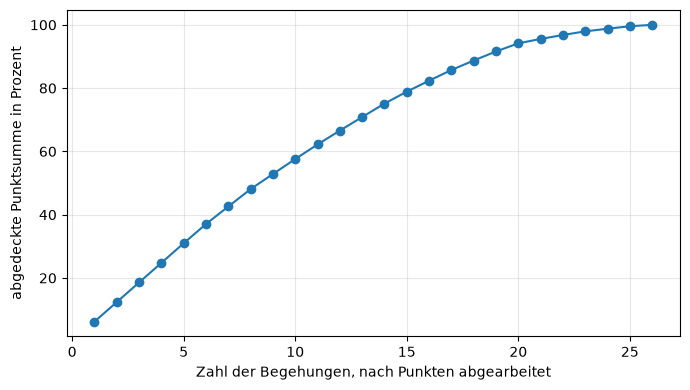

In [21]:
ab = em.abdeckung(treffer)
for n in (5, 10, 15, 20):
    if n <= len(ab):
        zeile = ab.iloc[n - 1]
        print(f"{n:2d} Begehungen decken {100 * zeile['anteil_punkte']:.0f} "
              f"Prozent der Punktsumme ab")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ab["n_begehungen"], 100 * ab["anteil_punkte"], marker="o")
ax.set_xlabel("Zahl der Begehungen, nach Punkten abgearbeitet")
ax.set_ylabel("abgedeckte Punktsumme in Prozent")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

In [22]:
winter = pd.read_csv(ROOT / "data" / "processed" /
                     "wintervergleich_kernwinter.csv")
nutzen = em.nutzenbilanz(treffer, winter)
print(nutzen["tafel"].to_string(index=False))
print(f"\nauswertbare Begehungen: {nutzen['n_begehungen']}")
print(f"ohne messbare Verbesserung: {nutzen['n_ohne_wirkung']} "
      f"({100 * nutzen['anteil_ohne_wirkung']:.0f} Prozent)")
print(f"davon in der Trefferliste: {nutzen['ohne_wirkung_erkannt']}")
print(f"Trefferquote bei schlechtem Zustand danach: "
      f"{100 * nutzen['trefferquote_schlecht']:.0f} Prozent")
print(f"Anteil der guten Faelle in der Liste: "
      f"{100 * nutzen['fehlalarm_gut']:.0f} Prozent")

zustand_vor zustand_nach  nicht_erkannt  in_trefferliste
        gut          gut             24                2
        gut     schlecht              1                3
   schlecht          gut              3                2
   schlecht     schlecht              5                4

auswertbare Begehungen: 44
ohne messbare Verbesserung: 9 (20 Prozent)
davon in der Trefferliste: 4
Trefferquote bei schlechtem Zustand danach: 54 Prozent
Anteil der guten Faelle in der Liste: 13 Prozent


- 10 Begehungen decken 58 % der Punktsumme ab, 20 Begehungen 94 %.
- 9 von 44 Begehungen ohne messbare Verbesserung, 4 davon in der Trefferliste.
- Schlechter Zustand nach der Begehung: 54 % in der Liste, guter Zustand: 13 %.

## 10 Lauf-Kontext

- Schwellen, Gewichte und Kernergebnisse in `data/processed/empfehlung_kontext.json`.

In [23]:
kontext = {
    "panel": {"zeilen": int(len(panel)),
              "stationen": int(panel["meter"].nunique()),
              "von": str(panel["datum"].min().date()),
              "bis": str(panel["datum"].max().date())},
    "kurzschlusscluster": int(KURZ),
    "tagesschwellen": {k: float(v) for k, v in schwellen.items()},
    "musterkatalog": [m["name"] for m in em.MUSTERKATALOG],
    "schwellen": {"min_evidenz": em.MIN_EVIDENZ,
                  "min_persistenz": em.MIN_PERSISTENZ,
                  "stufe_hoch": em.STUFE_HOCH,
                  "stufe_mittel": em.STUFE_MITTEL},
    "gewichte": {"abweichung": em.W_ABWEICHUNG,
                 "persistenz": em.W_PERSISTENZ,
                 "effizienz": em.W_EFFIZIENZ},
    "treffer": {"n": int(len(treffer)),
                "je_stufe": treffer["stufe"].value_counts().to_dict(),
                "ohne_muster": int((treffer["muster"] == em.OHNE_MUSTER).sum())},
    "freitexte": ft.kodierbilanz(kodiert).set_index("stufe")["n_texte"].to_dict(),
    "baum": {"r2_mittel": float(stab["r2_test"].mean()),
             "r2_streuung": float(stab["r2_test"].std()),
             "wurzeln": sorted(set(stab["wurzel"]))},
}
pfad = ROOT / "data" / "processed" / "empfehlung_kontext.json"
pfad.write_text(json.dumps(kontext, indent=2, ensure_ascii=False),
                encoding="utf-8")
print(json.dumps(kontext, indent=2, ensure_ascii=False))
tick("fertig")

{
  "panel": {
    "zeilen": 105513,
    "stationen": 100,
    "von": "2021-05-31",
    "bis": "2026-07-20"
  },
  "kurzschlusscluster": 4,
  "tagesschwellen": {
    "score_residuum_netz": 22.718456615108874,
    "score_residuum_station": 8.207776616702136
  },
  "musterkatalog": [
    "Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss",
    "Hoher Ruecklauf im Sommer, Verdacht Zirkulations- oder Speicherverlust",
    "Unruhige Regelung",
    "Ruecklauf reagiert kaum, Verdacht festsitzendes oder offenes Ventil",
    "Keine nennenswerte Abnahme bei warmem Ruecklauf",
    "Ruecklauf dauerhaft ueber der Netzerwartung",
    "Verschlechterung gegenueber dem eigenen Normalbetrieb"
  ],
  "schwellen": {
    "min_evidenz": 0.6,
    "min_persistenz": 0.1,
    "stufe_hoch": 55.0,
    "stufe_mittel": 30.0
  },
  "gewichte": {
    "abweichung": 0.45,
    "persistenz": 0.35,
    "effizienz": 0.2
  },
  "treffer": {
    "n": 26,
    "je_stufe": {
      "hoch": 16,
      "niedrig": 6,
 

## Zusammenfassung & Bewertung

Ergebnis
- 25 von 26 auffälligen Stationen mit Muster statt 21 ohne verwertbare Diagnose, 16 mit hohem Schweregrad.

Belastbar
- Die Restkategorie war ein Konstruktionsfehler, keine Eigenschaft der Daten.
- Kurzschlussverdacht physikalisch konsistent, der Baum findet dieselbe Konstellation stabil als wärmsten Ast.
- Nach der Begehung trennt die Liste schlechte von guten Fällen.

Schwach
- Text- und Messrangliste laufen auseinander, ein Teil der Protokolle beschreibt nur das Gebäude.
- 68956351 wird als Kurzschluss statt Ventil eingeordnet.
- Schweregrad nur aus Rücklaufsicht. Fünf Zähler haben ein Jahr mehr Beobachtungszeit.

Offen
- Muster zu Maßnahme ist physikalisch begründet, bleibt aber ein Vorschlag für die ÜZ.
- Mindestevidenz, Persistenzschwelle, Stufen und Gewichte sind gesetzt, nicht kalibriert.
- Trennung von offenem Ventil und Kurzschluss im Messbild.